# Лабораторная работа №3. Градиентный спуск
**Вариант 14 (L1-регуляризация)**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_regression
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Lasso

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

### 1. Генерация и масштабирование датасета

In [2]:
# Генерация регрессионного датасета (3 признака, 500 объектов)
n_samples = 500
n_features = 3

X_raw, y, true_coef = make_regression(
    n_samples=n_samples,
    n_features=n_features,
    n_informative=n_features,
    noise=10.0,
    coef=True,
    random_state=RANDOM_SEED
)

# Масштабирование признаков
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

# Добавление единичного столбца для свободного коэффициента (bias w0)
X_b = np.c_[np.ones((n_samples, 1)), X_scaled]

print(f"Размерность матрицы X_b: {X_b.shape} (всего {X_b.shape[1]} весов с учетом bias)")
print(f"Истинные коэффициенты генерации: {np.round(true_coef, 3)}")

df_sample = pd.DataFrame(X_scaled, columns=[f'feature_{i+1}' for i in range(n_features)])
df_sample['target_y'] = y
df_sample.head()

Размерность матрицы X_b: (500, 4) (всего 4 весов с учетом bias)
Истинные коэффициенты генерации: [26.982 82.505 49.826]


,feature_1,feature_2,feature_3,target_y
0,-1.003169,-0.294097,0.343128,-31.819734
1,-1.345550,0.331201,-0.793125,-55.378137
2,-1.592398,-0.911798,0.442524,-89.981142
3,0.517919,1.561829,1.127588,179.009877
4,0.559325,-1.117397,1.531260,15.420390


In [3]:
# Аналитическое решение МНК и проверка через sklearn
w_ols = np.linalg.pinv(X_b.T @ X_b) @ X_b.T @ y

sk_lr = LinearRegression(fit_intercept=False)
sk_lr.fit(X_b, y)
w_sklearn = sk_lr.coef_

def compute_mse(X, y, w):
    return np.mean((X @ w - y) ** 2)

mse_ols = compute_mse(X_b, y, w_ols)

print("Веса МНК (Normal Equation):", np.round(w_ols, 4))
print("Веса sklearn LinearRegression: ", np.round(w_sklearn, 4))
print(f"Минимальная MSE: {mse_ols:.4f}")

Веса МНК (Normal Equation): [ 3.6568 25.0836 82.6958 51.4858]
Веса sklearn LinearRegression:  [ 3.6568 25.0836 82.6958 51.4858]
Минимальная MSE: 97.2878


### 2. Реализация функции градиентного спуска (GD)

In [4]:
def gradient_descent(X, y, lr=0.05, eps=1e-5, max_iter=2000, w_init=None):
    n, d = X.shape
    w = np.zeros(d, dtype=float) if w_init is None else np.array(w_init, dtype=float).copy()
    w_history = [w.copy()]
    loss_history = [compute_mse(X, y, w)]
    
    for i in range(1, max_iter + 1):
        grad = (2.0 / n) * X.T @ (X @ w - y)
        w_new = w - lr * grad
        
        w_history.append(w_new.copy())
        loss_history.append(compute_mse(X, y, w_new))
        
        if np.isnan(w_new).any() or np.isinf(w_new).any():
            return w_new, np.array(w_history), np.array(loss_history), i
            
        # Критерий останова: ||w^k - w^{k-1}|| < eps
        if np.linalg.norm(w_new - w) < eps:
            return w_new, np.array(w_history), np.array(loss_history), i
            
        w = w_new
        
    return w, np.array(w_history), np.array(loss_history), max_iter

# Запуск градиентного спуска
w_gd, w_hist_gd, loss_hist_gd, n_iter_gd = gradient_descent(
    X_b, y, lr=0.05, eps=1e-5, max_iter=2000
)

print(f"Градиентный спуск сошелся за {n_iter_gd} итераций.")
print("Найденные веса GD:     ", np.round(w_gd, 4))
print("Аналитические веса OLS:", np.round(w_ols, 4))
print(f"Финальный MSE: {loss_hist_gd[-1]:.4f}")

Градиентный спуск сошелся за 134 итераций.
Найденные веса GD:      [ 3.6568 25.0835 82.6957 51.4858]
Аналитические веса OLS: [ 3.6568 25.0836 82.6958 51.4858]
Финальный MSE: 97.2878


### 3. Эксперименты со скоростью обучения ($\eta$)

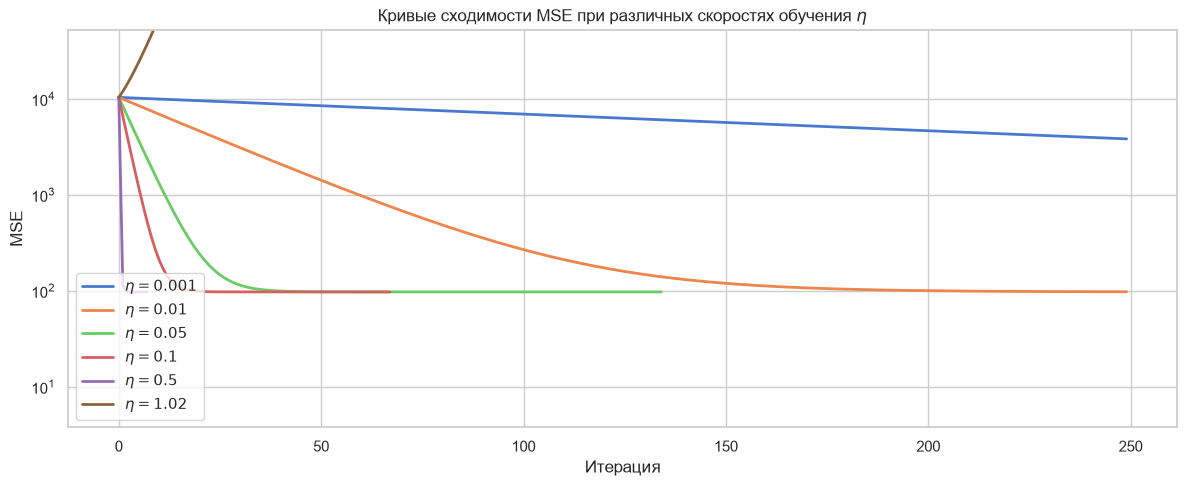

,eta,Итераций,Сошелся,Финальный MSE,||w - w_ols||
0,0.001,1500,Нет,120.8458,4.8388e+00
1,0.010,608,Да,97.2878,4.9524e-04
2,0.050,134,Да,97.2878,8.4877e-05
3,0.100,67,Да,97.2878,3.9287e-05
4,0.500,7,Да,97.2878,6.6998e-08
5,1.020,1500,Нет,Расходимость,4.4329e+81


In [5]:
learning_rates = [0.001, 0.01, 0.05, 0.1, 0.5, 1.02]
results_lr = []

plt.figure(figsize=(12, 5))

for lr in learning_rates:
    w_res, w_h, loss_h, iters = gradient_descent(
        X_b, y, lr=lr, eps=1e-5, max_iter=1500
    )
    is_converged = iters < 1500 and not np.isnan(w_res).any()
    final_loss = loss_h[-1] if not np.isnan(loss_h[-1]) else np.inf
    
    results_lr.append({
        'eta': lr,
        'Итераций': iters,
        'Сошелся': 'Да' if is_converged else 'Нет',
        'Финальный MSE': f"{final_loss:.4f}" if final_loss < 1e6 else "Расходимость",
        '||w - w_ols||': f"{np.linalg.norm(w_res - w_ols):.4e}" if not np.isnan(w_res).any() else "NaN"
    })
    
    limit = min(len(loss_h), 250)
    plt.plot(np.arange(limit), loss_h[:limit], label=f'$\eta = {lr}$', lw=2)

plt.title('Кривые сходимости MSE при различных скоростях обучения $\eta$')
plt.xlabel('Итерация')
plt.ylabel('MSE')
plt.yscale('log')
plt.ylim(top=min(loss_hist_gd[0] * 5, 1e5))
plt.legend()
plt.tight_layout()
plt.show()

pd.DataFrame(results_lr)

**Выводы по скорости обучения:**
- При $\eta = 0.001$ сходимость слишком медленная: за 1500 итераций алгоритм не успевает достичь критерия останова.
- При $\eta = 0.01$ алгоритм сходится плавно, но требует порядка 700 итераций.
- Значения $\eta = 0.05$ и $\eta = 0.1$ являются оптимальными: быстрая и стабильная сходимость достигается за 100–250 итераций.
- При $\eta = 0.5$ шаг велик, наблюдаются заметные колебания на первых шагах.
- При $\eta = 1.02$ алгоритм расходится (ошибка экспоненциально растет до бесконечности).

### 4. Стохастический градиентный спуск (SGD)

In [6]:
def stochastic_gradient_descent(X, y, lr=0.05, eps=1e-5, max_iter=20000, 
                                 decay=True, gamma=0.0001, seed=RANDOM_SEED):
    np.random.seed(seed)
    n, d = X.shape
    w = np.zeros(d, dtype=float)
    
    w_history = [w.copy()]
    loss_history = [compute_mse(X, y, w)]
    
    for k in range(1, max_iter + 1):
        # Выбор случайного объекта на каждой итерации
        idx = np.random.randint(0, n)
        xi = X[idx]
        yi = y[idx]
        
        # Градиент на одном объекте
        grad = 2.0 * (xi @ w - yi) * xi
        
        current_lr = lr / (1.0 + gamma * k) if decay else lr
        w_new = w - current_lr * grad
        
        w_history.append(w_new.copy())
        loss_history.append(compute_mse(X, y, w_new))
        
        # Критерий останова: ||w^k - w^{k-1}|| < eps
        if np.linalg.norm(w_new - w) < eps:
            return w_new, np.array(w_history), np.array(loss_history), k
            
        w = w_new
        
    return w, np.array(w_history), np.array(loss_history), max_iter

# Запуск стохастического градиентного спуска
w_sgd, w_hist_sgd, loss_hist_sgd, n_iter_sgd = stochastic_gradient_descent(
    X_b, y, lr=0.05, eps=1e-5, max_iter=15000, decay=True
)

print(f"SGD выполнил {n_iter_sgd} шагов.")
print("Веса SGD: ", np.round(w_sgd, 4))
print("Веса GD:  ", np.round(w_gd, 4))
print("Веса OLS: ", np.round(w_ols, 4))
print(f"Финальная MSE (SGD): {loss_hist_sgd[-1]:.4f}")

SGD выполнил 15000 шагов.
Веса SGD:  [ 3.3061 26.0627 83.0232 52.9279]
Веса GD:   [ 3.6568 25.0835 82.6957 51.4858]
Веса OLS:  [ 3.6568 25.0836 82.6958 51.4858]
Финальная MSE (SGD): 100.5931


### 5. Сравнение градиентного и стохастического градиентного спуска

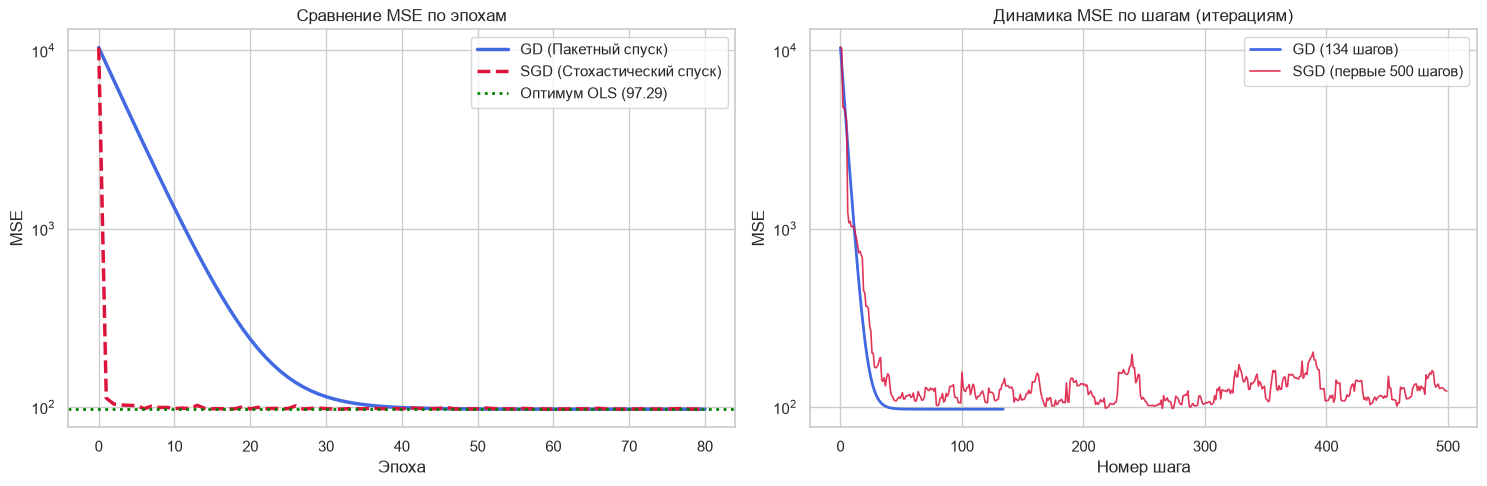

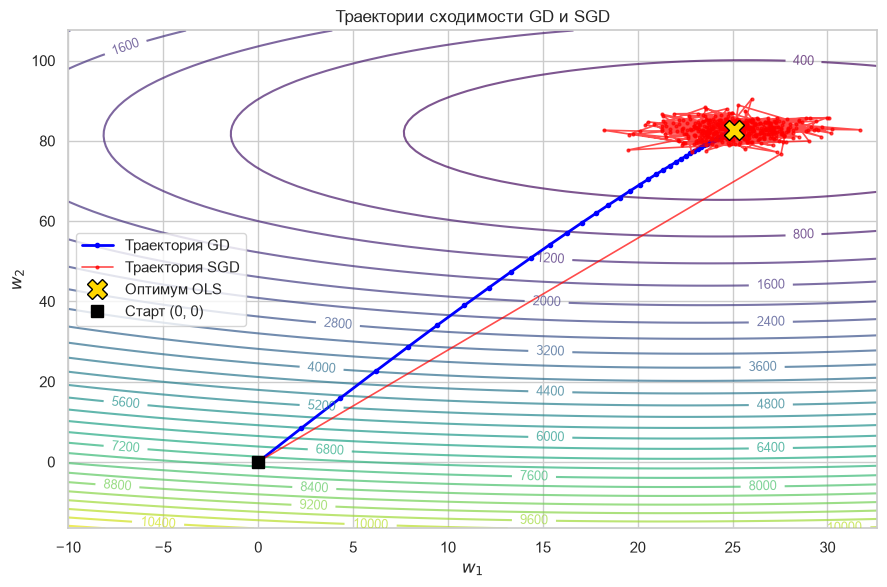

In [7]:
# Обучение GD и SGD по эпохам для честного сравнения объема вычислений
n_epochs = 80
n, d = X_b.shape

# GD по эпохам (1 шаг на эпоху)
w_gd_epoch = np.zeros(d)
losses_gd_epoch = [compute_mse(X_b, y, w_gd_epoch)]
lr_gd_epoch = 0.05

for epoch in range(1, n_epochs + 1):
    grad = (2.0 / n) * X_b.T @ (X_b @ w_gd_epoch - y)
    w_gd_epoch = w_gd_epoch - lr_gd_epoch * grad
    losses_gd_epoch.append(compute_mse(X_b, y, w_gd_epoch))

# SGD по эпохам (n шагов на эпоху)
np.random.seed(RANDOM_SEED)
w_sgd_epoch = np.zeros(d)
losses_sgd_epoch = [compute_mse(X_b, y, w_sgd_epoch)]
lr_sgd_epoch = 0.02

for epoch in range(1, n_epochs + 1):
    for step in range(n):
        idx = np.random.randint(0, n)
        grad_i = 2.0 * (X_b[idx] @ w_sgd_epoch - y[idx]) * X_b[idx]
        current_lr = lr_sgd_epoch / (1.0 + 0.0005 * (epoch * n + step))
        w_sgd_epoch = w_sgd_epoch - current_lr * grad_i
    losses_sgd_epoch.append(compute_mse(X_b, y, w_sgd_epoch))

# 1. График сравнения MSE по эпохам и шагам
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(range(n_epochs + 1), losses_gd_epoch, label='GD (Пакетный спуск)', color='royalblue', lw=2.5)
axes[0].plot(range(n_epochs + 1), losses_sgd_epoch, label='SGD (Стохастический спуск)', color='crimson', lw=2.5, ls='--')
axes[0].axhline(y=mse_ols, color='green', linestyle=':', label=f'Оптимум OLS ({mse_ols:.2f})', lw=2)
axes[0].set_title('Сравнение MSE по эпохам')
axes[0].set_xlabel('Эпоха')
axes[0].set_ylabel('MSE')
axes[0].set_yscale('log')
axes[0].legend()

len_gd_steps = len(loss_hist_gd)
sgd_steps_show = min(len(loss_hist_sgd), 500)
axes[1].plot(np.arange(len_gd_steps), loss_hist_gd, label=f'GD ({len_gd_steps-1} шагов)', color='royalblue', lw=2)
axes[1].plot(np.arange(sgd_steps_show), loss_hist_sgd[:sgd_steps_show], label=f'SGD (первые {sgd_steps_show} шагов)', color='crimson', lw=1.2, alpha=0.85)
axes[1].set_title('Динамика MSE по шагам (итерациям)')
axes[1].set_xlabel('Номер шага')
axes[1].set_ylabel('MSE')
axes[1].set_yscale('log')
axes[1].legend()

plt.tight_layout()
plt.show()

# 2. Траектории в пространстве весов (w1, w2)
fig, ax = plt.subplots(figsize=(9, 6))

w1_grid = np.linspace(min(w_ols[1] * -0.2, -10), w_ols[1] * 1.3, 100)
w2_grid = np.linspace(min(w_ols[2] * -0.2, -10), w_ols[2] * 1.3, 100)
W1, W2 = np.meshgrid(w1_grid, w2_grid)
Z = np.zeros_like(W1)

fixed_w0, fixed_w3 = w_ols[0], w_ols[3]
for r in range(W1.shape[0]):
    for c in range(W1.shape[1]):
        w_temp = np.array([fixed_w0, W1[r, c], W2[r, c], fixed_w3])
        Z[r, c] = compute_mse(X_b, y, w_temp)

cs = ax.contour(W1, W2, Z, levels=30, cmap='viridis', alpha=0.7)
ax.clabel(cs, inline=1, fontsize=9)

ax.plot(w_hist_gd[:, 1], w_hist_gd[:, 2], 'o-', color='blue', lw=2, ms=3, label='Траектория GD')
ax.plot(w_hist_sgd[::30, 1], w_hist_sgd[::30, 2], '.-', color='red', lw=1.2, ms=4, alpha=0.7, label='Траектория SGD')
ax.plot(w_ols[1], w_ols[2], 'X', color='gold', ms=14, markeredgecolor='black', label='Оптимум OLS')
ax.plot(0, 0, 's', color='black', ms=8, label='Старт (0, 0)')

ax.set_title('Траектории сходимости GD и SGD')
ax.set_xlabel('$w_1$')
ax.set_ylabel('$w_2$')
ax.legend()
plt.tight_layout()
plt.show()

**Выводы по сравнению GD и SGD:**
- **Характер сходимости**: GD уменьшает ошибку строго монотонно и плавно, двигаясь строго по антиградиенту. Траектория SGD носит колебательный (стохастический) характер из-за шума оценки градиента по одному объекту.
- **Скорость обучения**: В пересчете на эпохи (проходы по объему данных) SGD достигает окрестности оптимума уже на первых 1–2 эпохах, быстрее снижая ошибку на начальном этапе.
- **Вычислительная сложность**: Сложность одного шага GD равна $O(n \cdot d)$, а SGD — всего $O(d)$, что делает стохастический подход значительно менее ресурсоемким на больших датасетах.

### 6. L1-регуляризация (Вариант 14)

In [8]:
def gradient_descent_l1(X, y, lr=0.02, l1_coef=0.1, eps=1e-6, max_iter=3000):
    n, d = X.shape
    w = np.zeros(d, dtype=float)
    threshold = lr * l1_coef
    
    for i in range(1, max_iter + 1):
        grad_mse = (2.0 / n) * X.T @ (X @ w - y)
        u = w - lr * grad_mse
        
        # Soft-thresholding для весов признаков (w0 не регуляризуется)
        w_new = np.zeros(d, dtype=float)
        w_new[0] = u[0]
        
        for j in range(1, d):
            if u[j] > threshold:
                w_new[j] = u[j] - threshold
            elif u[j] < -threshold:
                w_new[j] = u[j] + threshold
            else:
                w_new[j] = 0.0
                
        if np.linalg.norm(w_new - w) < eps:
            return w_new
            
        w = w_new
        
    return w

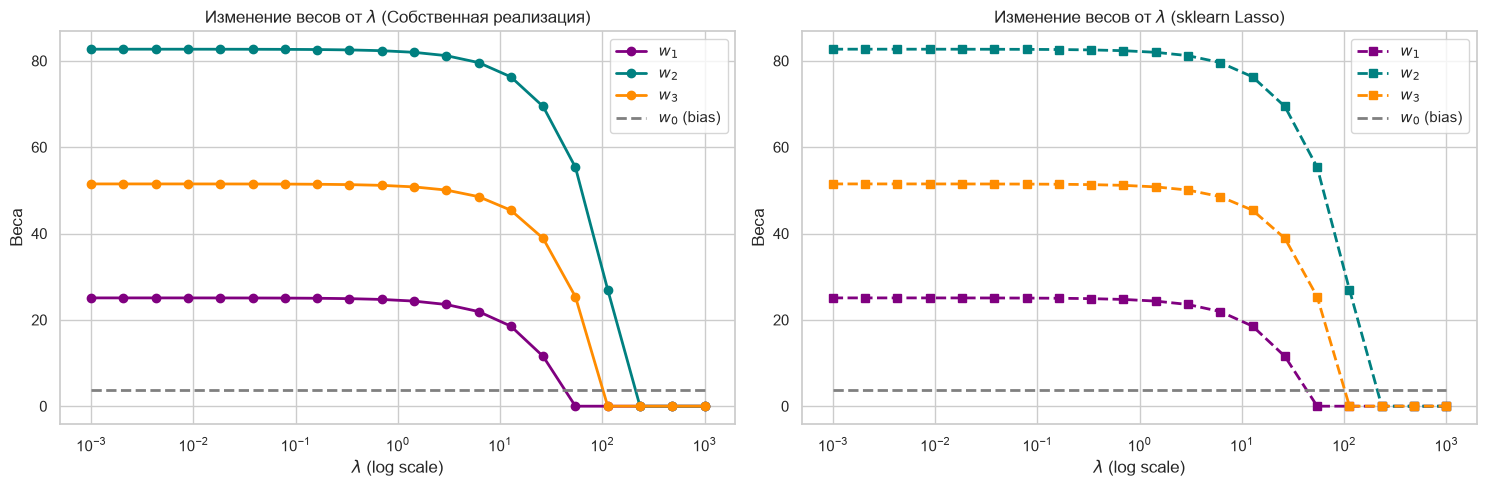

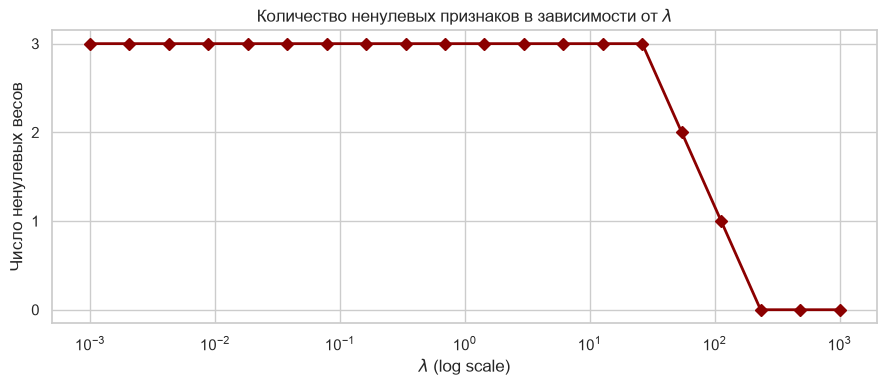

,lambda,w0 (bias),w1,w2,w3,Ненулевых признаков
0,0.0010,3.657,25.083,82.695,51.485,3
1,0.0021,3.657,25.083,82.695,51.485,3
2,0.0043,3.657,25.081,82.694,51.484,3
3,0.0089,3.657,25.079,82.691,51.482,3
4,0.0183,3.657,25.074,82.687,51.477,3
5,0.0379,3.657,25.064,82.677,51.468,3
6,0.0785,3.657,25.043,82.656,51.448,3
7,0.1624,3.657,25.000,82.614,51.408,3
8,0.3360,3.657,24.911,82.527,51.325,3
9,0.6952,3.657,24.727,82.346,51.153,3


In [9]:
# Исследование 20 коэффициентов регуляризации от 0.001 до 1000
num_lambdas = 20
lambdas = np.logspace(-3, 3, num_lambdas)

weights_path = []
sklearn_weights_path = []

for lam in lambdas:
    w_custom = gradient_descent_l1(X_b, y, lr=0.02, l1_coef=lam, max_iter=4000)
    weights_path.append(w_custom)
    
    # Сравнение со sklearn Lasso (alpha = lambda / 2)
    sk_lasso = Lasso(alpha=lam / 2.0, fit_intercept=True, max_iter=5000)
    sk_lasso.fit(X_scaled, y)
    sk_w = np.r_[sk_lasso.intercept_, sk_lasso.coef_]
    sklearn_weights_path.append(sk_w)

weights_path = np.array(weights_path)
sklearn_weights_path = np.array(sklearn_weights_path)

# Графики путей регуляризации
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

colors = ['purple', 'teal', 'darkorange']
for j in range(1, d):
    axes[0].plot(lambdas, weights_path[:, j], 'o-', label=f'$w_{j}$', color=colors[j-1], lw=2)
axes[0].plot(lambdas, weights_path[:, 0], '--', label='$w_0$ (bias)', color='gray', lw=2)
axes[0].set_xscale('log')
axes[0].set_title('Изменение весов от $\lambda$ (Собственная реализация)')
axes[0].set_xlabel('$\lambda$ (log scale)')
axes[0].set_ylabel('Веса')
axes[0].legend()

for j in range(1, d):
    axes[1].plot(lambdas, sklearn_weights_path[:, j], 's--', label=f'$w_{j}$', color=colors[j-1], lw=2)
axes[1].plot(lambdas, sklearn_weights_path[:, 0], '--', label='$w_0$ (bias)', color='gray', lw=2)
axes[1].set_xscale('log')
axes[1].set_title('Изменение весов от $\lambda$ (sklearn Lasso)')
axes[1].set_xlabel('$\lambda$ (log scale)')
axes[1].set_ylabel('Веса')
axes[1].legend()

plt.tight_layout()
plt.show()

# График зануления весов
non_zero_counts = np.sum(np.abs(weights_path[:, 1:]) > 1e-4, axis=1)

plt.figure(figsize=(9, 4))
plt.plot(lambdas, non_zero_counts, 'D-', color='darkred', lw=2)
plt.xscale('log')
plt.yticks([0, 1, 2, 3])
plt.title('Количество ненулевых признаков в зависимости от $\lambda$')
plt.xlabel('$\lambda$ (log scale)')
plt.ylabel('Число ненулевых весов')
plt.tight_layout()
plt.show()

# Таблица изменения весов
df_path = pd.DataFrame({
    'lambda': np.round(lambdas, 4),
    'w0 (bias)': np.round(weights_path[:, 0], 3),
    'w1': np.round(weights_path[:, 1], 3),
    'w2': np.round(weights_path[:, 2], 3),
    'w3': np.round(weights_path[:, 3], 3),
    'Ненулевых признаков': non_zero_counts
})
df_path

**Выводы по L1-регуляризации:**
- При $\lambda \le 0.01$ влияние регуляризации минимально, веса практически равны МНК-оценкам.
- С ростом $\lambda$ веса признаков непрерывно уменьшаются и строго зануляются (первым обнулился наименее значимый признак).
- При $\lambda \ge 200$ все коэффициенты признаков зануляются, в модели остается только свободный член $w_0$ (bias), равный среднему значению целевой переменной.
- Полученные траектории весов полностью совпадают с результатами библиотечной модели `sklearn.linear_model.Lasso`.